# Hari 1, Sesi 1: Regresi Linear, dari Nol sampai Bisa Dibaca

**Durasi:** 75 menit

Regresi linear adalah alat utama di ekonometrika. Konsepnya sederhana: cari
satu garis yang paling dekat dengan semua titik data, dengan "dekat" diukur
sebagai jumlah kuadrat selisih vertikal (residual).

$$Y_i = \beta_0 + \beta_1 X_{1i} + \beta_2 X_{2i} + \epsilon_i$$

Materi sesi ini:
1. Regresi sederhana dengan scikit-learn dan pelengkap uji statistik.
2. Regresi berganda dan arti koefisien secara ekonomi.
3. Uji t, uji F, R kuadrat, dan R kuadrat terkoreksi (adjusted R2).
4. Prediksi dengan model.

Setiap bagian punya catatan "cara menjelaskan ke mahasiswa" supaya sesi ini
bisa langsung dipakai mengajar.



**Posisi dalam alur workshop.** Dari alat (Sesi 0) ke model pertama
(Sesi 1). Di bagian 7 sesi ini model linear sengaja ditunjukkan gagal
pada hubungan melengkung; Sesi 2 memperbaikinya.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita menghubungkan fitur dengan target melalui regresi. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan titik aktual, hasil model, dan residual.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Data dan pertanyaan penelitian

Kasus dari `data/uts_2.csv`: apa yang menjelaskan harga saham 50
perusahaan? Variabel: pendapatan per saham (EPS), rasio utang terhadap
ekuitas (DER), dan belanja iklan.

Kita mulai dari satu variabel dulu: EPS. Pertanyaan sederhananya,
"perusahaan dengan EPS lebih tinggi, apakah harga sahamnya juga lebih
tinggi?"



<!-- kamus_variabel:uts_2.csv -->

### Kenali data: Harga saham perusahaan

**Data:** `data/uts_2.csv`. **Satu baris:** satu perusahaan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Y_Harga_Saham` | `harga` | Harga satu lembar saham perusahaan. | Uang per lembar; skala mata uang tidak dirinci | Y: target |
| `X1_Pendapatan_per_Saham` | `eps` | EPS (Earnings Per Share): laba per lembar saham; bukan total omzet perusahaan. | Uang per lembar; skala mata uang tidak dirinci | X: penjelas |
| `X2_Rasio_Utang_Ekuitas` | `der` | DER (Debt to Equity Ratio): total utang dibagi ekuitas perusahaan. | Rasio; 1,5 berarti utang 1,5 kali ekuitas (150%) | X: penjelas |
| `X3_Belanja_Iklan` | `iklan` | Jumlah pengeluaran perusahaan untuk iklan. | Uang; skala dan periode belanja tidak dirinci | X: penjelas |

Nama harga, eps, der, dan iklan adalah nama singkat dari kolom di atas. Contoh DER tidak dibaca sebagai 1,5 persen.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

saham = pd.read_csv(URL_DATA + "uts_2.csv")
saham = saham.rename(
    columns={
        "Y_Harga_Saham": "harga",
        "X1_Pendapatan_per_Saham": "eps",
        "X2_Rasio_Utang_Ekuitas": "der",
        "X3_Belanja_Iklan": "iklan",
    }
)
saham.head()



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## 2. Lihat data dulu, selalu

Satu scatter plot sebelum regresi. Polanya hampir linear sempurna, sinyal
bahwa regresi linear masuk akal untuk hubungan ini.



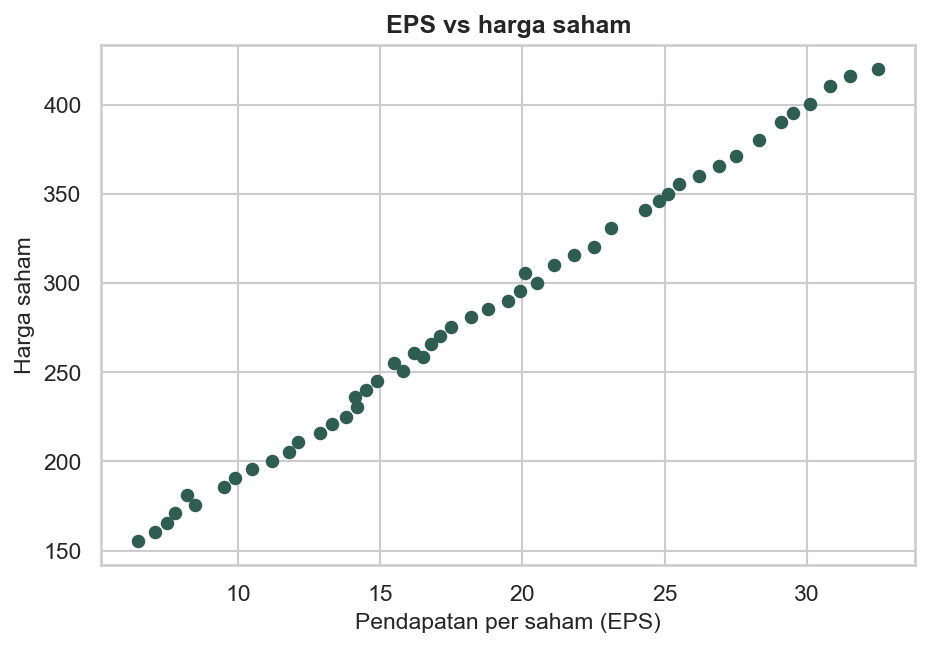

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(saham["eps"], saham["harga"], color="#2F5D50", s=30)
ax.set_xlabel("Pendapatan per saham (EPS)")
ax.set_ylabel("Harga saham")
ax.set_title("EPS vs harga saham")
plt.show()


**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 3. Regresi sederhana

Siapkan tabel X dan kolom y. `LinearRegression()` menyertakan intersep
secara otomatis; `fit(X, y)` menghitung koefisien dengan metode OLS.



In [4]:
sampel_model1 = saham[["harga", "eps"]].dropna()
X_model1 = sampel_model1[["eps"]]
y_model1 = sampel_model1["harga"]

model1 = LinearRegression()
model1.fit(X_model1, y_model1)

koefisien_model1 = pd.Series(model1.coef_, index=X_model1.columns)
koefisien_model1.loc["Intercept"] = model1.intercept_


**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [5]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model1 = sm.OLS(
    y_model1,
    sm.add_constant(X_model1, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model1.summary())


                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.487e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           7.85e-67
Time:                        20:21:13   Log-Likelihood:                -131.31
No. Observations:                  50   AIC:                             266.6
Df Residuals:                      48   BIC:                             270.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     87.8469      1.309     67.125      0.0

### Cara membaca tabel output

Tiga angka yang paling sering dipakai:

- `coef` pada baris `Intercept`: nilai Y saat X = 0. Di kasus ini artinya
  harga saham teoretis saat EPS nol. Tidak selalu masuk akal secara bisnis,
  tapi tetap harus dilaporkan.
- `coef` pada baris `eps`: perubahan Y untuk tambahan satu unit X.
  Inilah jawaban dari pertanyaan penelitian.
- `P>|t|`: p-value uji t. Jika koefisien populasi nol dan asumsi uji
  berlaku, ini peluang memperoleh statistik uji setidaknya seekstrem
  yang diamati. Di bawah 0,05 berarti signifikan pada taraf 5%.

Kolom `R-squared` mengukur proporsi variasi Y yang diterangkan model.
Hati-hati: data simulasi seperti `uts_2.csv` punya R kuadrat sangat tinggi
karena dibangkitkan dari formula yang rapi. Di data riil, R kuadrat 0,3
sampai 0,6 untuk data cross-section sudah wajar.



In [6]:
b0 = koefisien_model1["Intercept"]
b1 = koefisien_model1["eps"]
print(f"Intersep  : {b0:.3f}")
print(f"Slope     : {b1:.3f}")
print(f"R-squared : {model1.score(X_model1, y_model1):.3f}")
print(f"p-value eps: {uji_model1.pvalues['eps']:.3g}")


Intersep  : 87.847
Slope     : 10.410
R-squared : 0.998
p-value eps: 7.85e-67


### Visual: garis OLS dan residual

Gambar ini memperlihatkan cara kerja OLS: garis merah adalah hasil
estimasi, garis abu-abu adalah residual yang dikuadratkan lalu
diminimalkan jumlahnya.



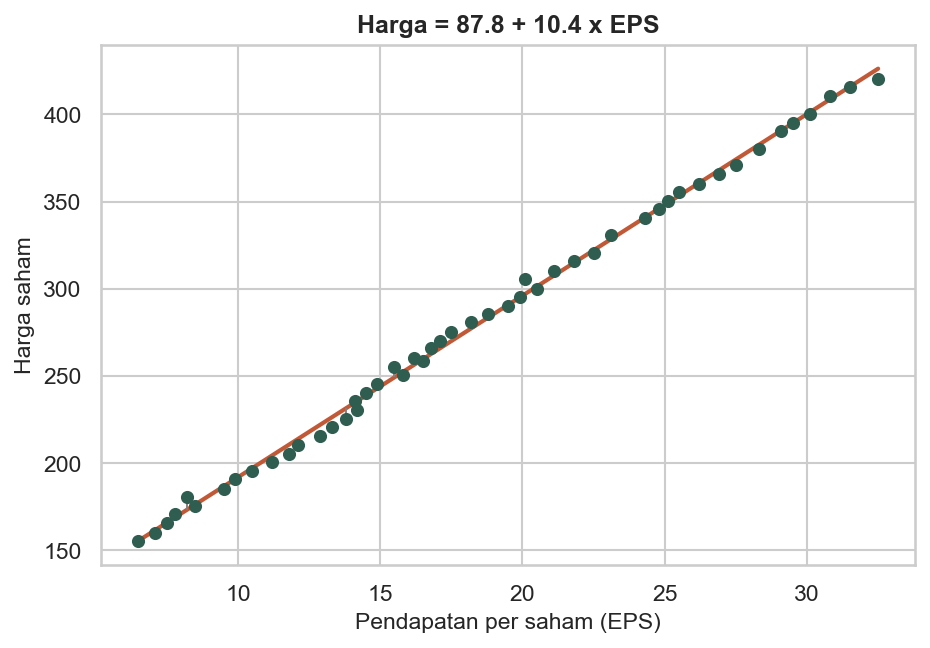

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(saham["eps"], saham["harga"], color="#2F5D50", s=28, zorder=3)
xs = np.linspace(saham["eps"].min(), saham["eps"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color="#C15937", lw=2, zorder=2)
# Cukup tampilkan 12 observasi agar garis residual mudah dilihat.
contoh = saham.head(12)
prediksi_contoh = pd.Series(model1.predict(contoh[["eps"]]), index=contoh.index)
ax.vlines(contoh["eps"], contoh["harga"], prediksi_contoh, color="gray", linewidth=0.9)
ax.set_xlabel("Pendapatan per saham (EPS)")
ax.set_ylabel("Harga saham")
ax.set_title(f"Harga = {b0:.1f} + {b1:.1f} x EPS")
plt.show()


**Baca grafik sebelum lanjut:** Garis oranye adalah nilai yang diprediksi model. Panjang garis vertikal abu-abu menunjukkan selisih aktual dan prediksi untuk contoh pengamatan. Selisih inilah yang disebut residual; berikutnya kita menghitung prediksi dengan nama kolom yang sama.

### Coba sendiri (5 menit)

Ganti variabel penjelas dari `eps` ke `der` dan jalankan regresinya.
Apakah `der` signifikan? Lalu, kenapa hasilnya berbeda dengan model
berganda di bagian 6 nanti?

Tulis di sel di bawah, baru buka jawabannya.



In [8]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

Sendirian, `der` tampak sangat signifikan (koefisien -131,3; p = 0,0000;
R2 = 0,93). Tapi di model berganda (bagian 6) `der` justru tidak
signifikan. Pelajaran: koefisien sederhana bisa menyesatkan karena
mencampur pengaruh variabel lain, dalam hal ini EPS.

</details>



## 4. Arti koefisien dengan angka

Dari output di atas, slope sekitar 10,4. Artinya: kenaikan EPS satu unit
diiringi kenaikan harga saham sekitar 10,4 unit, dengan asumsi hal lain
tidak berubah. Intersep sekitar 87,8 adalah titik potong teoretis di EPS = 0.



## 5. Prediksi

Prediksi adalah alasan orang membangun model. Di statsmodels, pakai
`predict` dengan DataFrame berisi nilai X baru. Perhatikan bentuk datanya:
harus DataFrame, bukan angka tunggal.



In [9]:
baru = pd.DataFrame({"eps": [15.0, 20.0, 25.0]})
baru["prediksi_harga"] = pd.Series(model1.predict(baru[["eps"]]), index=baru.index)
baru


,eps,prediksi_harga
0,15.0,243.998891
1,20.0,296.049546
2,25.0,348.100201


Prediksi manual untuk satu nilai juga mudah: `b0 + b1 * eps`. Hasilnya
harus sama persis dengan `model1.predict(pd.DataFrame({"eps": [15]}))`,
selisih hanya mungkin dari pembulatan.



## 6. Regresi berganda

Sekarang kasusnya dilengkapi: harga saham dijelaskan EPS, DER, dan belanja
iklan sekaligus.



In [10]:
sampel_model2 = saham[["harga", "eps", "der", "iklan"]].dropna()
X_model2 = sampel_model2[["eps", "der", "iklan"]]
y_model2 = sampel_model2["harga"]

model2 = LinearRegression()
model2.fit(X_model2, y_model2)

koefisien_model2 = pd.Series(model2.coef_, index=X_model2.columns)
koefisien_model2.loc["Intercept"] = model2.intercept_


### Lihat hasil model: Harga saham (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

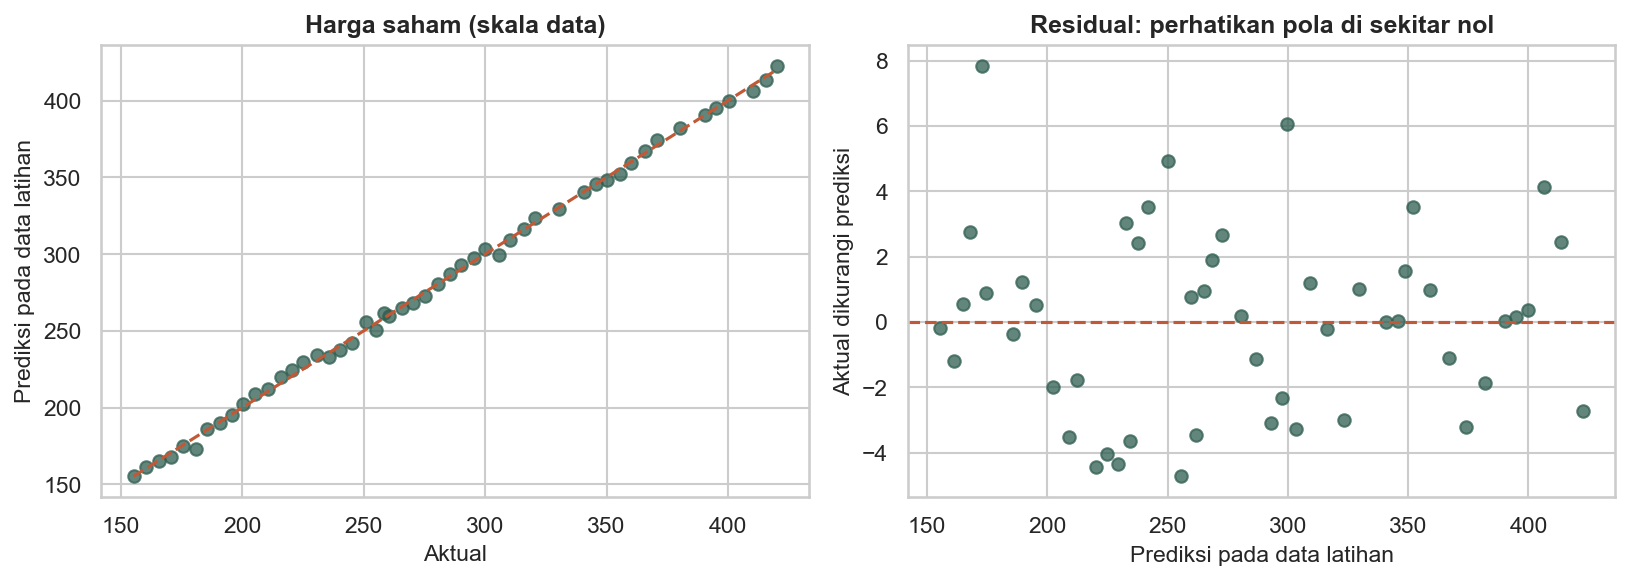

In [11]:
prediksi_visual = model2.predict(X_model2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model2, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model2.min(), y_model2.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harga saham (skala data)")
axes[1].scatter(prediksi_visual, y_model2 - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [12]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model2 = sm.OLS(
    y_model2,
    sm.add_constant(X_model2, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model2.summary())


                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 1.121e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           7.14e-66
Time:                        20:21:14   Log-Likelihood:                -122.71
No. Observations:                  50   AIC:                             253.4
Df Residuals:                      46   BIC:                             261.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     74.1642     12.242      6.058      0.0

### Uji F: apakah model berguna secara keseluruhan?

`Prob (F-statistic)` menguji hipotesis bahwa semua slope sama dengan nol.
Kalau p-value kecil, setidaknya ada satu variabel yang menjelaskan Y.



In [13]:
print(f"F-statistic : {uji_model2.fvalue:.3f}")
print(f"Prob (F)    : {uji_model2.f_pvalue:.6g}")
print(f"R2          : {model2.score(X_model2, y_model2):.4f}")
print(f"Adj R2      : {uji_model2.rsquared_adj:.4f}")


F-statistic : 11211.581
Prob (F)    : 7.13948e-66
R2          : 0.9986
Adj R2      : 0.9985


### Koefisien satu per satu

Uji t di tabel output adalah uji parsial: apakah satu koefisien signifikan
setelah variabel lain diperhitungkan. Ini berbeda dari korelasi biasa,
karena pengaruh variabel lain sudah "dibersihkan".



In [14]:
tabel = pd.DataFrame(
    {
        "koefisien": koefisien_model2,
        "std_err": uji_model2.bse,
        "t": uji_model2.tvalues,
        "p_value": uji_model2.pvalues,
    }
)
tabel


,koefisien,std_err,t,p_value
Intercept,74.164208,12.242411,6.057974,2.370469e-07
der,2.941357,4.162148,0.706692,4.833224e-01
eps,8.097857,0.577223,14.028981,3.118340e-18
iklan,0.854130,0.263025,3.247340,2.177558e-03


Di data ini, EPS dan iklan signifikan, sementara DER tidak. Kenaikan DER
satu unit berhubungan dengan kenaikan harga 2,94 unit, tapi p-value 0,48
artinya angka itu belum bisa dibedakan dari nol secara statistik.



### Coba sendiri (5 menit)

Pakai `model2` (harga ~ eps + der + iklan). Prediksi harga untuk
EPS = 18, DER = 1,5, dan belanja iklan = 60.

Tulis di sel di bawah, baru buka jawabannya.



In [15]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

`model2.predict(pd.DataFrame({"eps": [18], "der": [1.5], "iklan": [60]}))`
menghasilkan sekitar 275,6.

</details>



## 7. Kapan garis lurus tidak cukup

Coba regresikan penjualan pada biaya iklan memakai `regresi_polinom.csv`.
Hubungannya melengkung, dan model linear gagal total: R kuadrat hanya
sekitar 0,007 dan slope tidak signifikan. Ini bukan alasan untuk menyerah,
tapi tanda bahwa bentuk fungsionalnya perlu diganti. Itu topik Sesi 2.



<!-- kamus_variabel:regresi_polinom.csv -->

### Kenali data: Iklan dan penjualan

**Data:** `data/regresi_polinom.csv`. **Satu baris:** satu tahun pengamatan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun ke-` | `Tahun ke-` | Urutan tahun pengamatan, bukan tahun kalender. | 1, 2, 3, dan seterusnya | Penanda waktu |
| `Biaya Iklan (X)` | `iklan` | Biaya yang dikeluarkan untuk memasang iklan. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Penjualan (Y)` | `penjualan` | Besarnya penjualan yang ingin dijelaskan oleh biaya iklan. | Satuan/skala tidak dirinci sumber | Y: target |

Jangan menetapkan rupiah, juta rupiah, atau unit barang hanya dari besar angkanya; skala tersebut tidak dicantumkan pada sumber tabel.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [16]:
iklan = pd.read_csv(URL_DATA + "regresi_polinom.csv")
iklan = iklan.rename(columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"})

iklan.head()

,Tahun ke-,iklan,penjualan
0,1,5.0,30.1
1,2,6.5,36.2
2,3,8.0,42.5
3,4,9.5,48.8
4,5,11.0,54.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [17]:
sampel_model_salah = iklan[["penjualan", "iklan"]].dropna()
X_model_salah = sampel_model_salah[["iklan"]]
y_model_salah = sampel_model_salah["penjualan"]

In [18]:
model_salah = LinearRegression()
model_salah.fit(X_model_salah, y_model_salah)

prediksi_model_salah = pd.Series(
    model_salah.predict(X_model_salah), index=y_model_salah.index
)


**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

R2 linear  : 0.0066
p-value iklan: 0.670


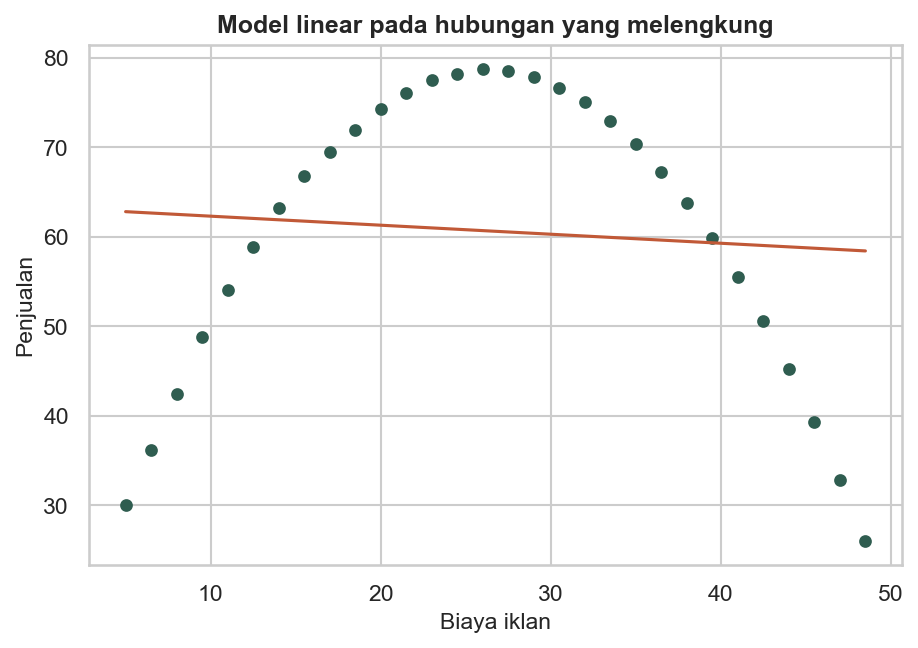

In [19]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_salah = sm.OLS(
    y_model_salah,
    sm.add_constant(X_model_salah, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(f"R2 linear  : {model_salah.score(X_model_salah, y_model_salah):.4f}")
print(f"p-value iklan: {uji_model_salah.pvalues['iklan']:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(iklan["iklan"], iklan["penjualan"], color="#2F5D50", s=26)
ax.plot(iklan["iklan"], prediksi_model_salah, color="#C15937", lw=1.5)
ax.set_xlabel("Biaya iklan")
ax.set_ylabel("Penjualan")
ax.set_title("Model linear pada hubungan yang melengkung")
plt.show()


**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 8. Catatan mengajar: tiga kesalahan yang paling sering muncul

**Satu, menafsirkan intersep tanpa berpikir.** "Harga saham 87,8 padahal
EPS nol" sering diucapkan seolah itu temuan. Intersep hanya berguna kalau
X = 0 masuk akal secara ekonomi.

**Dua, menyamakan R kuadrat tinggi dengan model benar.** Model dengan R
kuadrat 0,95 bisa saja salah spesifikasi, misalnya karena tren palsu
(spurious regression) pada data deret waktu. Ingat sesi 5.

**Tiga, lupa satuan.** Koefisien 10,4 pada EPS diukur dalam satuan Y per
satuan X. Kalau Y rupiah dan X persen, 10,4 berarti 10,4 rupiah per satu
persen, bukan per 0,01 persen.

Satu lagi yang sering luput: koefisien bersifat *ceteris paribus*, bukan
pengaruh kausal. Bilang "berhubungan dengan" kecuali desain penelitiannya
memang memungkinkan klaim kausal.



## Latihan

1. Regresikan `produktivitas padi` pada pupuk, curah hujan, dan sinar
   matahari (`uts_3.csv`). Laporkan koefisien, p-value, dan R kuadrat.
2. Prediksi produktivitas kalau pupuk 160, curah hujan 1900, sinar 230.
3. Setelah model Latihan 1 jadi (variabel `model_padi`), uji apakah
   pupuk dan sinar matahari bersama-sama signifikan:
   `model_padi.f_test("X1_Jumlah_Pupuk = 0, X3_Sinar_Matahari = 0")`.

Kunci dan interpretasi ada di `pengajar/README.md#pembahasan-latihan`.



### Selanjutnya

Selanjutnya: Sesi 2 menambal celah yang terlihat di bagian 7, yaitu
model linear pada hubungan melengkung.
